# 乳腺癌分类 —— 二分类（Classification）

**任务**：根据乳腺肿块细针穿刺的显微镜图像测量数据，判断肿块是**恶性**还是**良性**。

每个病人就是一行数字（30 个特征），我们要预测一个标签（0 或 1），所以这是一个**二分类**问题。

流程：加载数据 → 切分 + 标准化 → 训练逻辑回归并在测试集上评估 → 交叉验证比较逻辑回归和随机森林

In [1]:
# ===== 安装需要的库 =====
# "!" 开头表示运行的是终端命令，不是 Python 代码
# Colab 里这些库一般已经预装好了（所以输出都是 "Requirement already satisfied"），这一行只是保险
!pip install scikit-learn pandas numpy


## 1. 加载数据

- **X（特征）**：569 个病人 × 30 个特征。30 = 10 种细胞核测量（半径、纹理、周长、面积、光滑度……）× 3 个值（平均值、标准误差、最差值）
- **y（标签）**：⚠️ **0 = 恶性（malignant），1 = 良性（benign）** —— 和直觉相反！

In [2]:
# ===== 1. 加载数据 =====
# 569 名患者的乳腺肿块细针穿刺数据：从显微镜图像里测量细胞核的特征，标签是 恶性 / 良性

from sklearn.datasets import load_breast_cancer   # sklearn 自带的乳腺癌数据集，不用自己下载
import pandas as pd                               # 表格工具，可以理解成 Python 里的 Excel

data = load_breast_cancer()

# X：特征表（输入）。pd.DataFrame 把数组变成表格，columns 给每一列加上名字
# 比如 mean radius（平均半径）、mean texture（平均纹理），看表时就知道每一列是什么
X = pd.DataFrame(data.data, columns=data.feature_names)

# y：标签（答案）。pd.Series 是只有一列的表
#  0 = 恶性（malignant），1 = 良性（benign），可以用 data.target_names 查看
y = pd.Series(data.target, name="label")

# 数据大小：(569, 30) → 569 个病人，每人 30 个特征
# 30 = 10 种测量（半径、纹理、周长、面积、光滑度……）× 3 个值（平均值 mean、标准误差 error、最差值 worst）
print(X.shape)

# 每个标签有多少个：1（良性）357 个，0（恶性）212 个
# 两类数量不一样，叫"类别不平衡"，所以后面切分时要用 stratify
print(y.value_counts())

# 看前 5 个特征的 平均值 / 标准差 / 最小值 / 最大值
#   .describe() 计算统计量 → .T 转置（行列互换）→ [[...]] 选出这 4 列 → .head() 只看前 5 行
# 可以看到不同特征的数值范围差别很大：面积是几百，光滑度只有零点零几 → 所以后面要做标准化
print(X.describe().T[["mean", "std", "min", "max"]].head())


(569, 30)
label
1    357
0    212
Name: count, dtype: int64
                       mean         std        min        max
mean radius       14.127292    3.524049    6.98100    28.1100
mean texture      19.289649    4.301036    9.71000    39.2800
mean perimeter    91.969033   24.298981   43.79000   188.5000
mean area        654.889104  351.914129  143.50000  2501.0000
mean smoothness    0.096360    0.014064    0.05263     0.1634


## 1b. 可视化：在开始 machine learning 之前，先看特征的相关性

这里有 30 个特征，比糖尿病多很多，所以分两张图看：
- **左图**：每个特征和"是不是恶性"的相关性 → 哪些测量最能区分恶性和良性？
- **右图**：30 个特征彼此之间的相关性 → 有没有很多特征其实在说同一件事？

⚠️ 注意标签方向：数据集里 0 = 恶性、1 = 良性。为了好理解，这里新建一列 **malignant（恶性 = 1）** 来算相关，正相关就表示"这个值越大，越可能是恶性"。

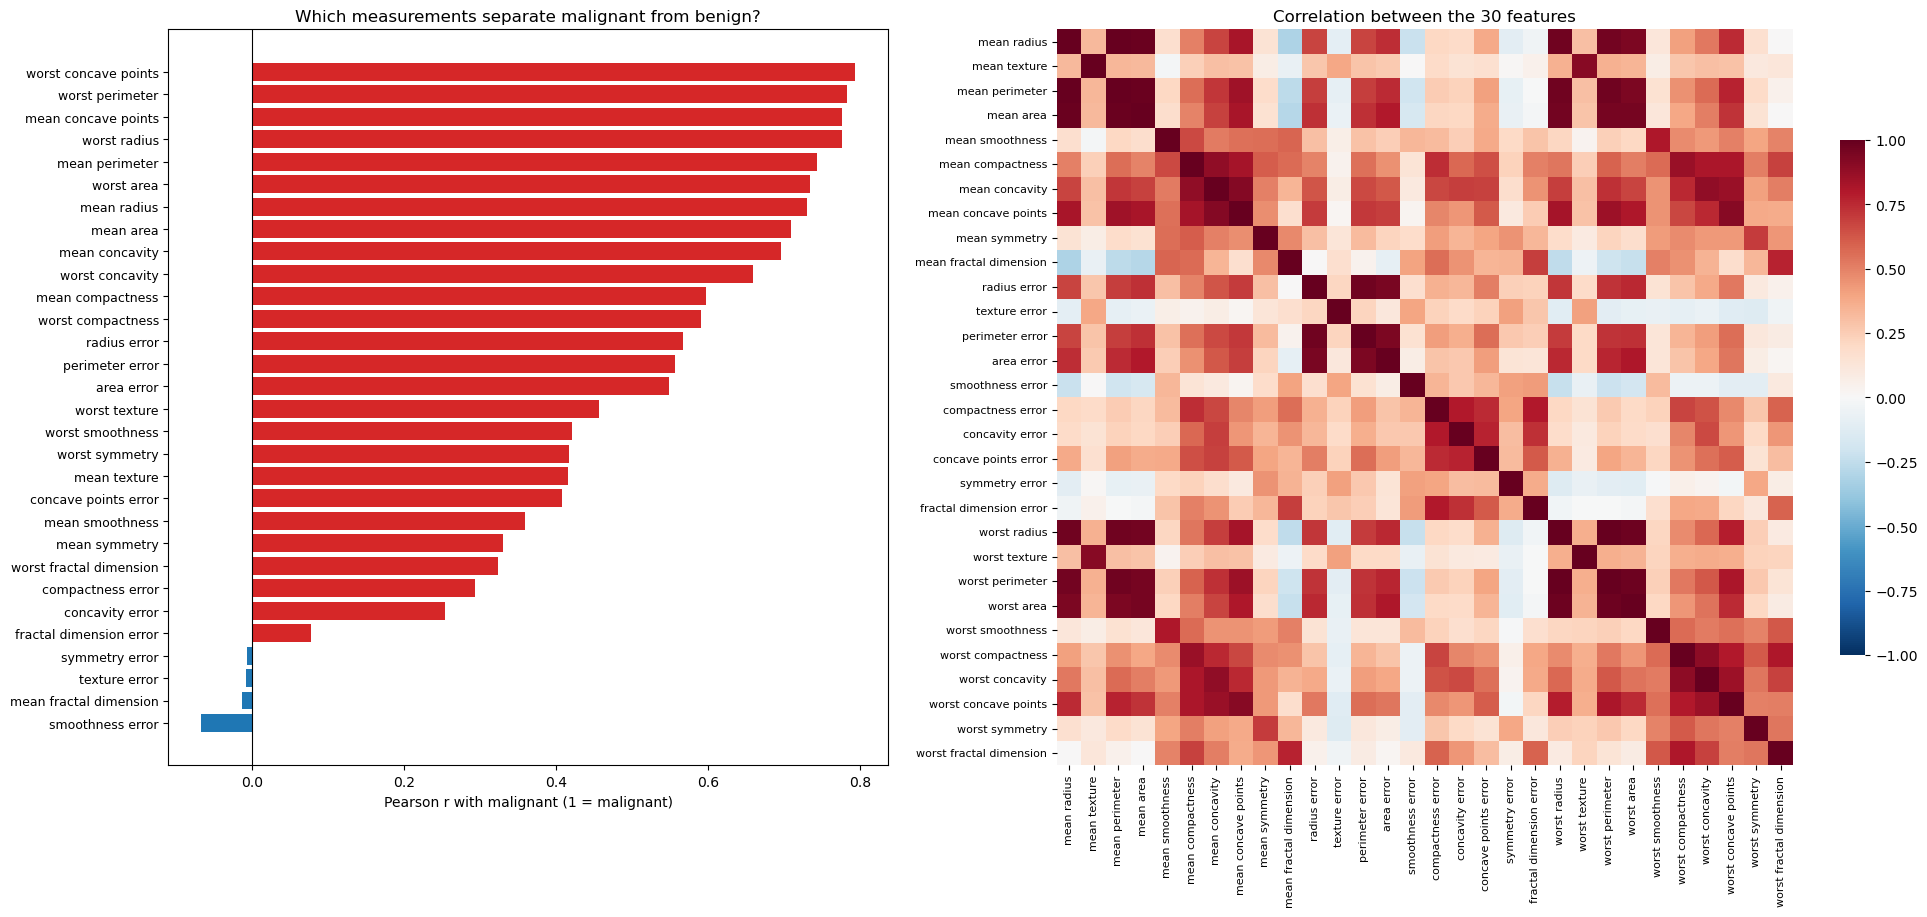

和恶性相关最强的 5 个特征：
worst concave points    0.79
worst perimeter         0.78
mean concave points     0.78
worst radius            0.78
mean perimeter          0.74
dtype: float64


In [3]:
# ===== 1b. 相关性可视化 =====
import matplotlib.pyplot as plt
import seaborn as sns          # 基于 matplotlib 的统计画图库，画热力图很方便（Colab 已预装）

# 新建一个"是不是恶性"的标签：原来 0 = 恶性，所以 (y == 0) 为 True 就是恶性，再转成 1/0
malignant = (y == 0).astype(int)

# X.corrwith(...)：计算 X 的每一列和 malignant 的 Pearson 相关系数，得到 30 个数
target_corr = X.corrwith(malignant).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(20, 9), gridspec_kw={"width_ratios": [1, 1.3]})

# 左图：30 个特征和"恶性"的相关系数，排好序画成横向柱状图（红 = 越大越可能恶性，蓝 = 相反）
colors = ["tab:red" if v > 0 else "tab:blue" for v in target_corr]
axes[0].barh(target_corr.index, target_corr.values, color=colors)
axes[0].axvline(0, color="black", linewidth=0.8)
axes[0].set_xlabel("Pearson r with malignant (1 = malignant)")
axes[0].set_title("Which measurements separate malignant from benign?")
axes[0].tick_params(axis="y", labelsize=9)

# 右图：30×30 的特征相关矩阵热力图。格子太多，所以不写数字（annot=False），只看颜色
#   X.corr() → 每两列之间的相关系数；vmin/vmax 固定 -1~1；center=0 让 0 是白色
sns.heatmap(X.corr(), cmap="RdBu_r", vmin=-1, vmax=1, center=0, square=True,
            ax=axes[1], cbar_kws={"shrink": 0.7}, xticklabels=True, yticklabels=True)
axes[1].tick_params(labelsize=8)
axes[1].set_title("Correlation between the 30 features")

plt.tight_layout()
plt.show()

# 打印和"恶性"相关最强的 5 个特征
print("和恶性相关最强的 5 个特征：")
print(target_corr.sort_values(ascending=False).head(5).round(2))

# 怎么读这两张图：
#   1. 左图：大部分特征都是正相关（红色）→ 细胞核越大、越不规则，越可能是恶性
#      最强的是 worst concave points、worst perimeter、mean concave points、worst radius（r 约 0.78~0.79）
#      → 单个特征就已经很有区分度了，这也解释了为什么一个简单的逻辑回归就能做到 AUC 0.99
#   2. 有几个特征几乎不相关（r 接近 0），比如 fractal dimension、texture error、smoothness error
#   3. 右图：有很多深红色的"方块"。比如 radius（半径）、perimeter（周长）、area（面积）彼此相关接近 1
#      —— 这很合理：知道了半径，周长和面积基本就确定了。它们其实在说同一件事（"多重共线性"）
#   4. 对比糖尿病：那里最强的特征 r 只有 0.59，R² 只有 0.45；这里特征强得多，所以分类效果好得多
#      → 先看相关性，往往就能预感到模型大概能做到什么程度

## 2. 切分训练集/测试集 + 标准化

- **训练集**：让模型学习；**测试集**：学习时完全看不到，最后用来"考试"，代表未来的新病人
- `stratify=y`：分层抽样，让训练集和测试集里恶性/良性的比例一样（因为两类数量不平衡）
- **标准化**：不同特征数值范围差别很大（面积几百、光滑度零点零几），标准化后每一列都是 均值0、标准差1
- 标准化**只在训练集上 fit**，测试集只用 `transform`，避免**数据泄漏**

In [4]:
# ===== 2. 切分训练集/测试集 + 标准化 =====

from sklearn.model_selection import train_test_split   # 把数据随机分成训练集和测试集
from sklearn.preprocessing import StandardScaler       # 标准化：每一列变成 均值0、标准差1

# 训练集：让模型学习；测试集：学习时完全看不到，最后用来"考试"，代表未来的新病人
#   test_size=0.2   → 20% 做测试集：569 人里 455 人训练，114 人测试
#   stratify=y      → 分层抽样：训练集和测试集里 恶性/良性 的比例和原始数据一样
#                     （不然随机分时，测试集里的恶性病人可能特别少，结果不可靠）
#   random_state=42 → 固定随机种子，保证每次切分结果一样（42 没有特殊含义）
# 返回顺序固定：X_train, X_test, y_train, y_test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# 为什么要标准化？不同特征的单位和大小差别很大（面积几百、光滑度零点零几），
# 逻辑回归这类模型会被"数字大"的特征主导。标准化 = 每一列 减去均值、再除以标准差
scaler = StandardScaler()

# fit_transform = fit（从训练集学出每列的均值和标准差） + transform（用它们转换训练集）
X_train_scaled = scaler.fit_transform(X_train)

# 测试集只用 transform：用"训练集"学到的均值和标准差来转换
# 测试集代表未来的病人，训练时不能用它的任何信息（包括它的均值），否则就是"数据泄漏"
X_test_scaled = scaler.transform(X_test)


## 3. 训练逻辑回归 + 测试集评估

**逻辑回归**：名字里有"回归"，但其实是**分类**模型。它给每个特征一个权重，加起来得到一个分数，再用 sigmoid 函数变成 0~1 之间的概率。

**评估指标**：
| 指标 | 含义 |
|---|---|
| precision（精确率） | 模型说是这一类的里面，真的是这一类的比例 |
| recall（召回率 / 敏感度） | 真的是这一类的里面，被模型找出来的比例 |
| f1-score | precision 和 recall 的综合 |
| accuracy（准确率） | 所有病人里猜对的比例 |
| AUC | 模型整体区分两类的能力；1 = 完美，0.5 = 瞎猜 |

**医学里两种错误不一样严重**：把恶性判成良性（漏诊）比把良性判成恶性（误诊）严重得多，所以要特别关注**恶性那一类的 recall**。

In [5]:
# ===== 3. 训练逻辑回归 + 测试集评估 =====

from sklearn.linear_model import LogisticRegression                # 逻辑回归：名字里有"回归"，但其实是分类模型
from sklearn.metrics import classification_report, roc_auc_score   # 分类的评估指标

# 建模型：逻辑回归给每个特征一个权重，加起来得到一个分数，再用 sigmoid 函数变成 0~1 的概率
#   max_iter=1000   → 最多迭代 1000 次（默认 100 次有时不够，会报"没收敛"的警告）
#   random_state=42 → 固定随机种子，结果可复现
model = LogisticRegression(max_iter=1000, random_state=42)

# 训练：模型看着训练集的特征和答案，学出每个特征的权重（sklearn 里所有模型都是 .fit 这个写法）
model.fit(X_train_scaled, y_train)

# 预测类别：直接给出 0 或 1（默认以概率 0.5 为分界线）
y_pred = model.predict(X_test_scaled)

# 预测概率：predict_proba 返回两列 —— 第 0 列是类别 0 的概率，第 1 列是类别 1 的概率，两列加起来 = 1
# [:, 1] 意思是"所有行，取第 1 列"
# ⚠️ 因为 1 = 良性，所以 y_prob 是"良性的概率"，不是"得癌的概率"
y_prob = model.predict_proba(X_test_scaled)[:, 1]

# classification_report 打印每一类的指标：
#   precision（精确率）：模型说是这一类的里面，真的是这一类的比例
#   recall（召回率/敏感度）：真的是这一类的里面，被模型找出来的比例
#   f1-score：precision 和 recall 的综合；support：测试集里这一类的真实数量
# 结果：恶性 42 个里找出 41 个（漏诊 1 个），良性 72 个里 71 个正确（误诊 1 个），准确率 98%
# 医学里漏诊（恶性判成良性）比误诊严重得多，所以要特别关注 恶性那一类（0）的 recall
print(classification_report(y_test, y_pred))

# AUC：ROC 曲线下面积，看模型整体区分两类的能力，不依赖 0.5 这个分界线
# 1.0 = 完美，0.5 = 和瞎猜一样；这里约 0.995，说明几乎能把两类完全分开
print("AUC:", roc_auc_score(y_test, y_prob))


              precision    recall  f1-score   support

           0       0.98      0.98      0.98        42
           1       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114

AUC: 0.9953703703703703


## 4. 交叉验证：比较逻辑回归和随机森林

**为什么要交叉验证？** 测试集只有 114 人，只切一次结果不稳定。5 折交叉验证把**训练集**分成 5 份，轮流用 1 份验证、4 份训练，得到 5 个分数，看平均值和波动：

```
第1次：[验证] [训练] [训练] [训练] [训练]
第2次：[训练] [验证] [训练] [训练] [训练]
第3次：[训练] [训练] [验证] [训练] [训练]
第4次：[训练] [训练] [训练] [验证] [训练]
第5次：[训练] [训练] [训练] [训练] [验证]
```

**随机森林**：由很多棵决策树组成，每棵树像一连串"是/否"问题（比如"半径 > 15 吗？"），最后所有树投票。

下面先看一个**有数据泄漏**的写法（❌），再看修正后的写法（✅）。

In [6]:
# ===== 4. 交叉验证：比较逻辑回归和随机森林=====
# 为什么要交叉验证？测试集只有 114 人，只切一次结果不稳定。
# 5 折交叉验证：把训练集分成 5 份，轮流用 1 份验证、4 份训练，得到 5 个分数，看平均值和波动
# 注意：交叉验证只在训练集上做，测试集一直不碰

from sklearn.model_selection import cross_val_score    # 自动做 K 折交叉验证，返回每一折的分数
from sklearn.ensemble import RandomForestClassifier    # 随机森林：很多棵决策树投票

# cross_val_score(模型, X, y, cv=5, scoring="roc_auc") → 做 5 折，每一折算一个 AUC，返回 5 个数

#    分成 5 折后，每一折的"验证部分"的信息已经在标准化时被用到了，相当于偷看了答案 → 数据泄漏
scores_lr = cross_val_score(
    LogisticRegression(max_iter=1000),
    X_train_scaled, y_train, cv=5, scoring="roc_auc"
)
# ❌ 问题：这里传入的是 X_train_scaled —— 它是用【整个训练集】的均值和标准差标准化的。

# 随机森林：n_estimators=200 → 200 棵决策树，每棵树用随机抽的数据和特征，最后投票决定结果
scores_rf = cross_val_score(
    RandomForestClassifier(n_estimators=200, random_state=42),
    X_train_scaled, y_train, cv=5, scoring="roc_auc"
)

# 打印 平均值 +/- 标准差；%.4f 表示保留 4 位小数
print("LR AUC: %.4f +/- %.4f" % (scores_lr.mean(), scores_lr.std()))
print("RF AUC: %.4f +/- %.4f" % (scores_rf.mean(), scores_rf.std()))


LR AUC: 0.9936 +/- 0.0106
RF AUC: 0.9874 +/- 0.0145


## 4b. 修正：用 pipeline 防止数据泄漏

上面的写法把**已经标准化好的** `X_train_scaled` 传进交叉验证。但它是用整个训练集的均值和标准差算的，所以每一折的验证部分其实已经"参与"了标准化 —— 这就是**数据泄漏**。

**修正方法**：用 `make_pipeline` 把 `StandardScaler` 和模型串起来，传入**未标准化的** `X_train`，让每一折只在自己的训练部分上 fit 标准化。

In [7]:
# ===== 4b. 交叉验证（✅ 修正后的写法：用 pipeline 防止数据泄漏）=====

from sklearn.pipeline import make_pipeline   # 新增这一行 import：把几个步骤串成一条"流水线"

# make_pipeline(StandardScaler(), LogisticRegression()) 把"标准化 + 逻辑回归"当成一个整体模型。
# 这样交叉验证的每一折里会自动：
#   ① 只在这一折的 4 份训练数据上 fit 标准化
#   ② 用它去 transform 这一折的验证数据
#   ③ 训练、评估
# 所以每一折都遵守"只在训练部分上 fit"的原则，验证部分不会泄漏进去
scores_lr = cross_val_score(
    make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),  # 改：标准化放进 pipeline
    X_train, y_train, cv=5, scoring="roc_auc"                            # 改：传未标准化的 X_train
)

# 随机森林不需要标准化：决策树只比较"大于还是小于某个值"，整列放大缩小不影响比较结果
scores_rf = cross_val_score(
    RandomForestClassifier(n_estimators=200, random_state=42),           # 树模型不需要标准化
    X_train, y_train, cv=5, scoring="roc_auc"                            # 改：同上
)

print("LR AUC: %.4f +/- %.4f" % (scores_lr.mean(), scores_lr.std()))
print("RF AUC: %.4f +/- %.4f" % (scores_rf.mean(), scores_rf.std()))

# 结果：LR AUC ≈ 0.9935 +/- 0.0108，RF AUC ≈ 0.9874 +/- 0.0145
# 解读：
#   1. 和上一个单元格（有泄漏）比，结果几乎一样 —— 这个数据集上泄漏影响很小，
#      但这是好习惯：在样本少、特征多的医学数据上，泄漏可能让结果虚高很多
#   2. 两个模型都很好；逻辑回归略高，但差距（约 0.006）比波动（约 0.01）还小，不能说明显更好
#   3. 复杂模型不一定更好：这里简单的逻辑回归就够了，而且更容易解释（可以直接看每个特征的权重）

LR AUC: 0.9935 +/- 0.0108
RF AUC: 0.9874 +/- 0.0145


## 5. 可视化：比较逻辑回归和随机森林

三类图：
1. **交叉验证 AUC**：两个模型在 5 折上的平均分和波动
2. **ROC 曲线**（测试集）：曲线越靠近左上角越好，曲线下的面积就是 AUC
3. **混淆矩阵**（测试集）：每个模型具体错在哪里

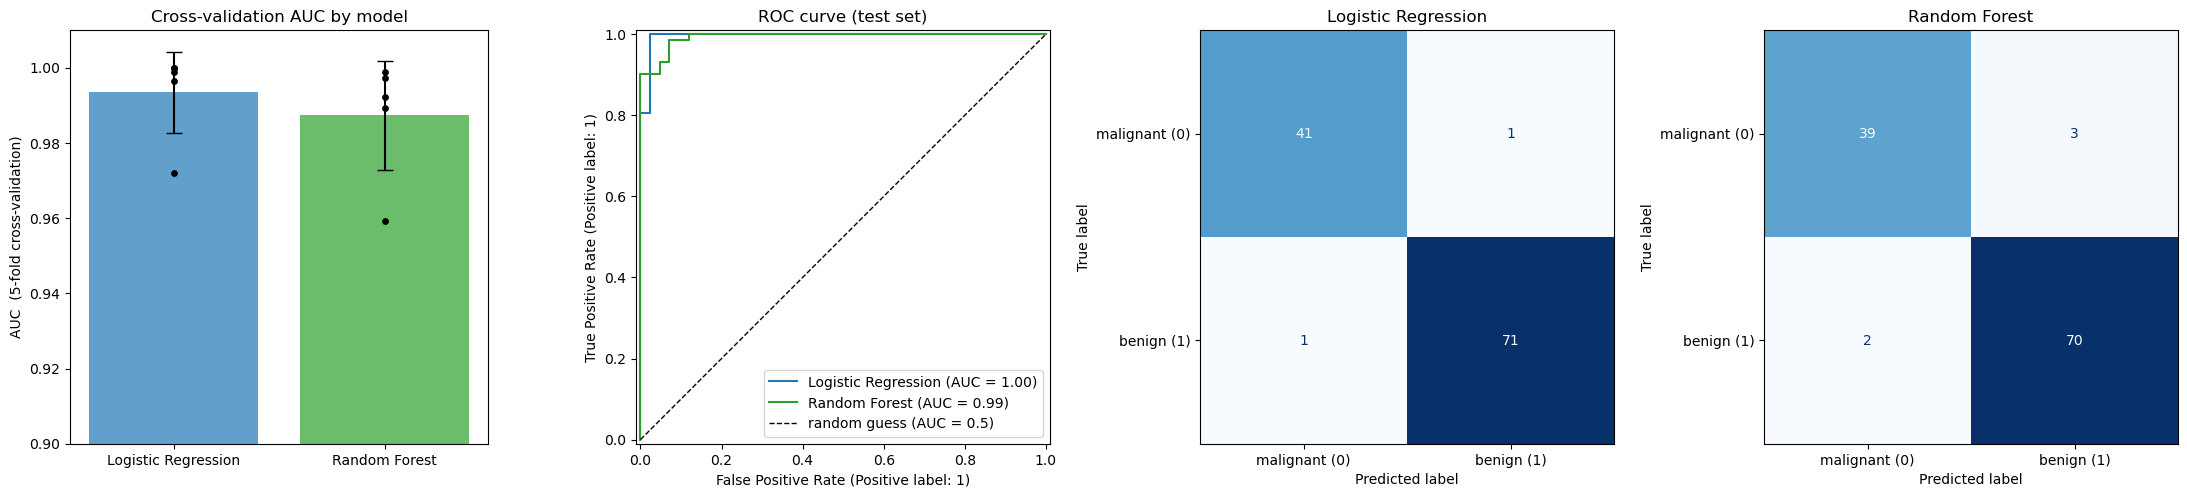

In [8]:
# ===== 5. 可视化不同模型的结果 =====
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay, ConfusionMatrixDisplay   # sklearn 自带的画 ROC 和混淆矩阵的工具

# 两个模型都在训练集上训练一次（和 4b 一样：逻辑回归放进 pipeline，随机森林直接用原始数据）
clf_models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42)),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
}
for m in clf_models.values():
    m.fit(X_train, y_train)

colors = ["tab:blue", "tab:green"]
fig, axes = plt.subplots(1, 4, figsize=(22, 5))

# 图1：交叉验证 AUC（直接用上面 4b 算好的 scores_lr 和 scores_rf）
#   柱子 = 5 折平均值；误差线 = 标准差；黑点 = 每一折的分数
cv = {"Logistic Regression": scores_lr, "Random Forest": scores_rf}
names = list(cv)
axes[0].bar(names, [cv[n].mean() for n in names], yerr=[cv[n].std() for n in names],
            capsize=6, color=colors, alpha=0.7)
for i, n in enumerate(names):
    axes[0].scatter([i] * len(cv[n]), cv[n], color="black", s=15, zorder=3)
axes[0].set_ylim(0.9, 1.01)          # 分数都很高，把纵轴放大，差别才看得清
axes[0].set_ylabel("AUC  (5-fold cross-validation)")
axes[0].set_title("Cross-validation AUC by model")

# 图2：ROC 曲线（测试集）
#   横轴 FPR（假阳性率）：真的是 0 的里面，被错判成 1 的比例
#   纵轴 TPR（真阳性率 = recall）：真的是 1 的里面，被找出来的比例
#   把判断的分界线从 1 慢慢降到 0，就得到一条曲线。曲线越靠近左上角越好
#   ⚠️ 这里默认把类别 1（良性）当作"阳性"；换成恶性当阳性，AUC 数值不变
for (name, m), c in zip(clf_models.items(), colors):
    RocCurveDisplay.from_estimator(m, X_test, y_test, name=name, ax=axes[1], color=c)
axes[1].plot([0, 1], [0, 1], "k--", linewidth=1, label="random guess (AUC = 0.5)")
axes[1].legend(loc="lower right")
axes[1].set_title("ROC curve (test set)")

# 图3、4：混淆矩阵（测试集）。行 = 真实，列 = 预测；对角线上是猜对的，其他格子是猜错的
for ax, (name, m) in zip(axes[2:], clf_models.items()):
    ConfusionMatrixDisplay.from_estimator(m, X_test, y_test, ax=ax, cmap="Blues", colorbar=False,
                                          display_labels=["malignant (0)", "benign (1)"])
    ax.set_title(name)

plt.tight_layout()
plt.show()

# 怎么读：
#   1. 图1：两个模型的 AUC 都在 0.98 以上，误差线重叠很多 → 差别不显著
#   2. 图2：两条 ROC 曲线都紧贴左上角，远高于对角虚线（瞎猜）
#      图例里逻辑回归显示 AUC = 1.00，只是因为保留两位小数四舍五入，实际约 0.995，并不是完美
#   3. 图3、4：重点看右上角的格子 = 真的恶性（第一行）却被预测成良性（第二列）= 漏诊，这是医学里最危险的错误
#      逻辑回归漏诊 1 个，随机森林漏诊更多；两个模型的总错误数都很少

# 糖尿病病情进展预测 —— 回归（Regression）

**任务**：根据 442 名糖尿病患者的基线数据（年龄、性别、BMI、血压、6 项血液指标），预测他们**一年后的病情进展程度**。

和乳腺癌分类不同，这里的标签是一个**连续的数字**（25 ~ 346），不是"恶性/良性"两类，所以这是一个**回归**问题。

流程：加载数据 → 切分 + 标准化 → 训练 Ridge 回归并在测试集上评估 → 交叉验证比较三个模型

## 0. 导入需要的工具

In [9]:
# ===== 0. 导入工具 =====
# 基本上都来自 scikit-learn（sklearn），Python 里最常用的传统机器学习库

from sklearn.datasets import load_diabetes                          # sklearn 自带的糖尿病数据集，不用自己下载
from sklearn.model_selection import train_test_split, cross_val_score  # 切分训练/测试集；交叉验证
from sklearn.preprocessing import StandardScaler                    # 标准化：每一列变成 均值0、标准差1
from sklearn.pipeline import make_pipeline                          # 把"标准化 + 模型"串成一条流水线
from sklearn.dummy import DummyRegressor                            # 基线模型：什么都不学，只猜一个固定值
from sklearn.linear_model import Ridge                              # 岭回归：带 L2 正则化的线性回归
from sklearn.ensemble import RandomForestRegressor                  # 随机森林回归：很多棵决策树取平均
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score  # 回归的评估指标
import pandas as pd                                                 # 表格工具，可以理解成 Python 里的 Excel

## 1. 加载数据

- **X（特征）**：10 列 —— `age` 年龄、`sex` 性别、`bmi` 体重指数、`bp` 平均血压，`s1`~`s6` 是 6 项血液检查指标（如总胆固醇、LDL、HDL、血糖等）
- **y（标签）**：一年后的病情进展程度，数字越大表示病情越重

In [10]:
# ===== 1. 加载数据 =====
# 442 名糖尿病患者，10 个特征，标签是一年后的病情进展（连续数值）

# scaled=False：拿原始单位的数据（比如年龄就是真实岁数）
# 默认 scaled=True 时 sklearn 已经帮你缩放过了，这里我们想自己做标准化，所以要原始数据
data = load_diabetes(scaled=False)

# X：特征表。pd.DataFrame 把数组变成表格，columns 给每一列加上名字
X = pd.DataFrame(data.data, columns=data.feature_names)

# y：标签（答案）。pd.Series 是只有一列的表
y = pd.Series(data.target, name="progression")

# 看一下数据的大小：(行数=病人数, 列数=特征数)
print(X.shape)        # 输出 (442, 10)

# 看一下标签的分布：平均值、标准差、最小值、最大值
# 平均约 152，标准差约 77，范围 25 ~ 346
print(y.describe()[["mean", "std", "min", "max"]])

(442, 10)
mean    152.133484
std      77.093005
min      25.000000
max     346.000000
Name: progression, dtype: float64


In [11]:
# （可选）看看前 5 个病人长什么样
X.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,59.0,2.0,32.1,101.0,157.0,93.2,38.0,4.0,4.8598,87.0
1,48.0,1.0,21.6,87.0,183.0,103.2,70.0,3.0,3.8918,69.0
2,72.0,2.0,30.5,93.0,156.0,93.6,41.0,4.0,4.6728,85.0
3,24.0,1.0,25.3,84.0,198.0,131.4,40.0,5.0,4.8903,89.0
4,50.0,1.0,23.0,101.0,192.0,125.4,52.0,4.0,4.2905,80.0


## 1b. 可视化：在开始 machine learning 之前，先看特征的相关性

先别急着训练模型，先看看数据：
- 哪些特征和**病情进展**关系最大？
- 特征**之间**是不是高度相关（信息重叠）？

**Pearson 相关系数 r**：范围 -1 ~ 1。正数 = 一个变大另一个也变大；负数 = 一个变大另一个变小；接近 0 = 没有**线性**关系。

⚠️ 相关 ≠ 因果；而且 r 只能反映线性关系。

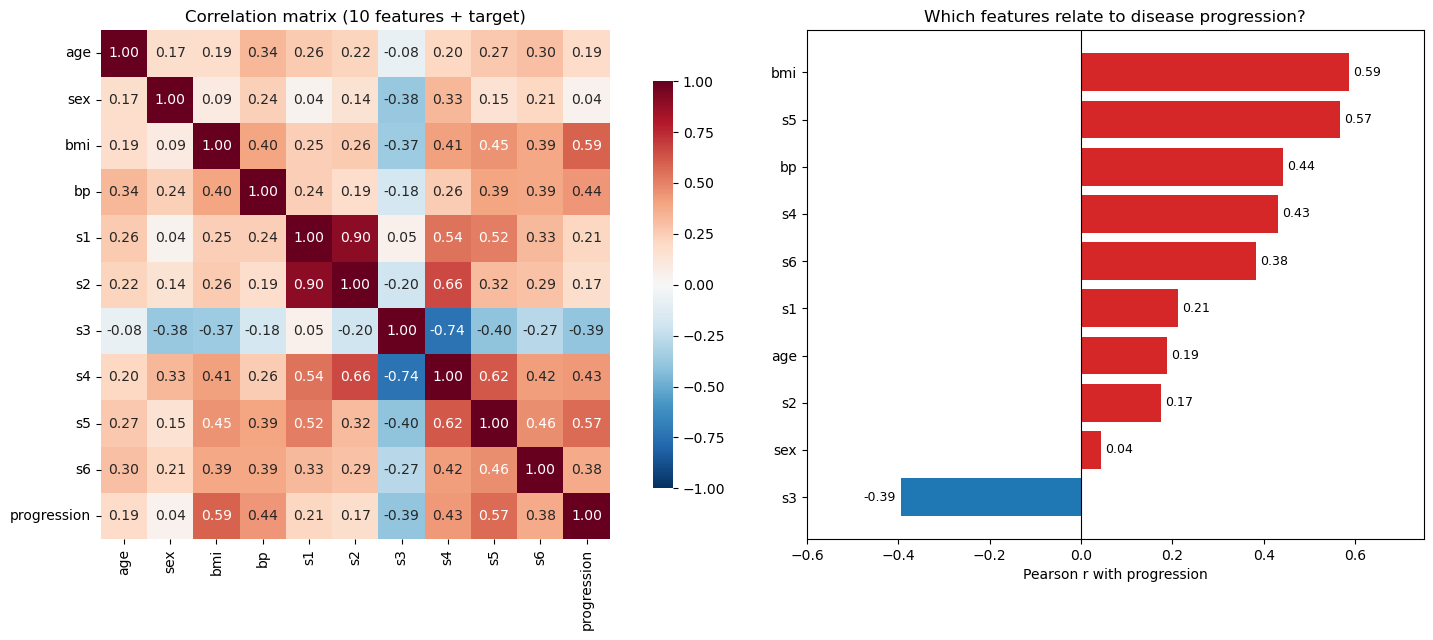

In [12]:
# ===== 1b. 相关性可视化 =====
import matplotlib.pyplot as plt
import seaborn as sns          # 基于 matplotlib 的统计画图库，画热力图很方便（Colab 已预装）

# 把特征和标签放进同一张表，一起计算相关系数
df = X.copy()
df["progression"] = y

# .corr()：计算每两列之间的 Pearson correlation coefficient；Pearson 相关系数，得到 11×11 的矩阵（10 个特征 + 1 个标签）
corr = df.corr()

# 一行两张图；width_ratios 让左边的热力图宽一点
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw={"width_ratios": [1.4, 1]})

# 左图：相关系数热力图。红色 = 正相关，蓝色 = 负相关，颜色越深相关越强
#   annot=True → 在格子里写数值；fmt=".2f" → 保留 2 位小数
#   vmin/vmax → 颜色范围固定为 -1~1；center=0 → 0 是白色
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, center=0,
            square=True, ax=axes[0], cbar_kws={"shrink": 0.8})
axes[0].set_title("Correlation matrix (10 features + target)")

# 右图：每个特征和标签的相关系数，排好序画成横向柱状图
#   corr["progression"] → 取出"和标签的相关"那一列；.drop 去掉它自己（自己和自己 r=1）
target_corr = corr["progression"].drop("progression").sort_values()
colors = ["tab:red" if v > 0 else "tab:blue" for v in target_corr]
axes[1].barh(target_corr.index, target_corr.values, color=colors)
axes[1].axvline(0, color="black", linewidth=0.8)           # 画一条 r=0 的竖线
for i, v in enumerate(target_corr.values):                 # 在柱子旁边写上数值
    axes[1].text(v + (0.01 if v > 0 else -0.01), i, "%.2f" % v,
                 va="center", ha="left" if v > 0 else "right", fontsize=9)
axes[1].set_xlim(-0.6, 0.75)
axes[1].set_xlabel("Pearson r with progression")
axes[1].set_title("Which features relate to disease progression?")

plt.tight_layout()
plt.show()

# 怎么读这两张图：
#   1. 和病情进展相关最强的是 bmi（约 0.59）、s5（约 0.57，血清甘油三酯）、bp（约 0.44，血压）、
#      s4（约 0.43，总胆固醇/HDL 比值）→ 体重、血脂、血压越高，一年后病情越重，符合医学常识
#   2. s3 是负相关（约 -0.39）：s3 是 HDL（"好胆固醇"），越高进展越轻
#   3. 特征之间：s1 和 s2 的相关高达约 0.90，s3 和 s4 约 -0.74，说明有些特征的信息高度重叠（叫"多重共线性"）
#      → 这正是我们用 Ridge（带 L2 正则化）的原因之一：它在高度相关的特征上更稳定
#   4. 但是没有任何一个特征 r 超过 0.6 → 单靠某一个指标很难预测，后面的 R² 只有 0.45 也就不奇怪了

## 2. 切分训练集/测试集 + 标准化

- **训练集**：让模型学习；**测试集**：模型学习时完全看不到，最后用来"考试"，代表未来的新病人
- 回归没有"类别"，所以**不需要** `stratify`（分类问题里才用它来保持各类比例）
- 标准化**只在训练集上 fit**，测试集只用 `transform`，避免**数据泄漏**

In [13]:
# ===== 2. 切分 + 标准化 =====

# train_test_split：把数据随机分成训练集和测试集
#   test_size=0.2   → 20% 做测试集：442 人里 353 人训练，89 人测试
#   random_state=42 → 固定随机种子，保证每次切分结果一样（42 没有特殊含义）
#   回归没有类别，所以不用 stratify
# 返回顺序固定：X_train, X_test, y_train, y_test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 为什么要标准化？不同特征的单位差别很大（年龄几十岁、血液指标可能上百），
# 线性模型会被"数字大"的特征主导。标准化后每一列都是 均值0、标准差1
scaler = StandardScaler()

# fit_transform = fit（从训练集学出每列的均值和标准差） + transform（用它们转换训练集）
X_train_scaled = scaler.fit_transform(X_train)

# 测试集只用 transform：用"训练集"学到的均值和标准差来转换
# 测试集代表未来的病人，训练时不能用它的任何信息（包括均值），否则就是数据泄漏
X_test_scaled = scaler.transform(X_test)

print("训练集:", X_train.shape, " 测试集:", X_test.shape)

训练集: (353, 10)  测试集: (89, 10)


## 3. 训练 Ridge 回归 + 测试集评估

**Ridge（岭回归）** = 线性回归 + L2 正则化：
- 线性回归：预测值 = w₁×age + w₂×bmi + … + 截距，学出每个特征的权重 w
- L2 正则化：额外惩罚太大的权重，让模型不要"过度相信"某一个特征，减少过拟合
- `alpha` 控制惩罚的强度，越大权重越小；`alpha=0` 就是普通线性回归

**三个评估指标**：
| 指标 | 含义 | 越…越好 |
|---|---|---|
| MAE（平均绝对误差） | 平均每个病人预测差了多少 | 越小 |
| RMSE（均方根误差） | 类似 MAE，但对大误差惩罚更重 | 越小 |
| R²（决定系数） | 模型解释了标签变化的多少比例；1 = 完美，0 = 和猜平均值一样 | 越大 |

In [14]:
# ===== 3. 训练 + 测试集评估 =====

# 建模型：带 L2 正则的线性回归，alpha=1.0 是正则化强度
model = Ridge(alpha=1.0)

# 训练：模型看着训练集的特征和答案，学出每个特征的权重
model.fit(X_train_scaled, y_train)

# 预测：对测试集里每个病人给出一个预测的进展数值（连续数字，不是类别）
y_pred = model.predict(X_test_scaled)

# MAE：平均绝对误差 = 平均每个病人预测值和真实值差多少（和标签同一个单位）
print("MAE : %.2f" % mean_absolute_error(y_test, y_pred))

# RMSE：均方根误差 = 先平方再平均再开根号，大误差会被放大，所以通常比 MAE 大
# mean_squared_error 返回的是 MSE（没开根号），所以这里 ** 0.5 手动开根号
print("RMSE: %.2f" % mean_squared_error(y_test, y_pred) ** 0.5)

# R²：模型解释了多少比例的变化。1 是完美，0 等于一直猜平均值，负数比猜平均值还差
print("R2  : %.3f" % r2_score(y_test, y_pred))

# 结果大约：MAE ≈ 42.8，RMSE ≈ 53.8，R² ≈ 0.45
# 解读：标签的标准差约 77，模型把误差降到了约 54；R²≈0.45 说明只解释了一半左右的变化
# —— 只靠这 10 个基线指标，很难准确预测一年后的病情，这在医学数据里很常见

MAE : 42.81
RMSE: 53.78
R2  : 0.454


In [15]:
# （可选）看看每个特征的权重：数据已经标准化，所以权重大小可以直接比较
# 正数 = 这个特征越大，预测的进展越严重；负数 = 相反
pd.Series(model.coef_, index=X.columns).sort_values()

s1    -34.671954
sex   -11.448190
age     1.807342
s6      2.458139
s3      3.369914
s4     11.764260
bp     16.734300
s2     17.053075
bmi    25.732699
s5     31.378384
dtype: float64

## 4. 交叉验证：基线 / Ridge / 随机森林 三者对比

**为什么要交叉验证？** 测试集只有 89 人，只切一次结果不稳定。5 折交叉验证把训练集分成 5 份，轮流用 1 份验证、4 份训练，得到 5 个分数，看平均值和波动。

**为什么要有基线（Baseline）？** 它什么都不学，永远猜训练集的平均值。一个模型至少要比它好，才说明真的学到了东西。

In [16]:
# ===== 4. 交叉验证：三个模型对比 =====

# 用字典把三个模型放在一起，方便循环。格式是 {名字: 模型}
models = {
    # 基线：永远预测训练集的平均值，R² 应该在 0 附近
    "Baseline": DummyRegressor(strategy="mean"),

    # Ridge：注意要用 pipeline 把标准化放进去！
    # 这样每一折都只在自己的训练部分上 fit 标准化，验证部分不会泄漏进去
    "Ridge": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),

    # 随机森林：200 棵决策树取平均。树只比较"大于/小于"，所以不需要标准化
    "RF": RandomForestRegressor(n_estimators=200, random_state=42),
}

# 对每个模型做 5 折交叉验证
for name, m in models.items():          # .items() 同时取出 名字 和 模型
    # 注意传入的是【未标准化】的 X_train：标准化交给 pipeline 在每一折里自己做
    # cv=5 → 5 折；scoring="r2" → 每一折算一个 R²，返回 5 个数
    s = cross_val_score(m, X_train, y_train, cv=5, scoring="r2")
    # %-8s：名字左对齐占 8 格，让输出对整齐；%.3f：保留 3 位小数
    print("%-8s R2: %.3f +/- %.3f" % (name, s.mean(), s.std()))

# 结果大约：
#   Baseline R2: -0.030 +/- 0.048   ← 和预期一样，接近 0
#   Ridge    R2:  0.451 +/- 0.139   ← 简单的线性模型反而最好
#   RF       R2:  0.398 +/- 0.143
# 解读：
#   1. 两个模型都远好于基线，说明确实学到了东西
#   2. Ridge 略好于随机森林，但差距（约 0.05）小于波动（约 0.14），不能说明显更好
#   3. 复杂模型不一定更好：样本少（几百人）时，简单的线性模型常常更稳，也更容易解释

Baseline R2: -0.030 +/- 0.048
Ridge    R2: 0.451 +/- 0.139
RF       R2: 0.398 +/- 0.143


## 5. 可视化：比较不同模型的结果

两类图：
1. **交叉验证 R²**：三个模型在 5 折上的平均分和波动
2. **测试集 "真实值 vs 预测值"**：每个点是一个病人。点越靠近红色对角线，预测越准

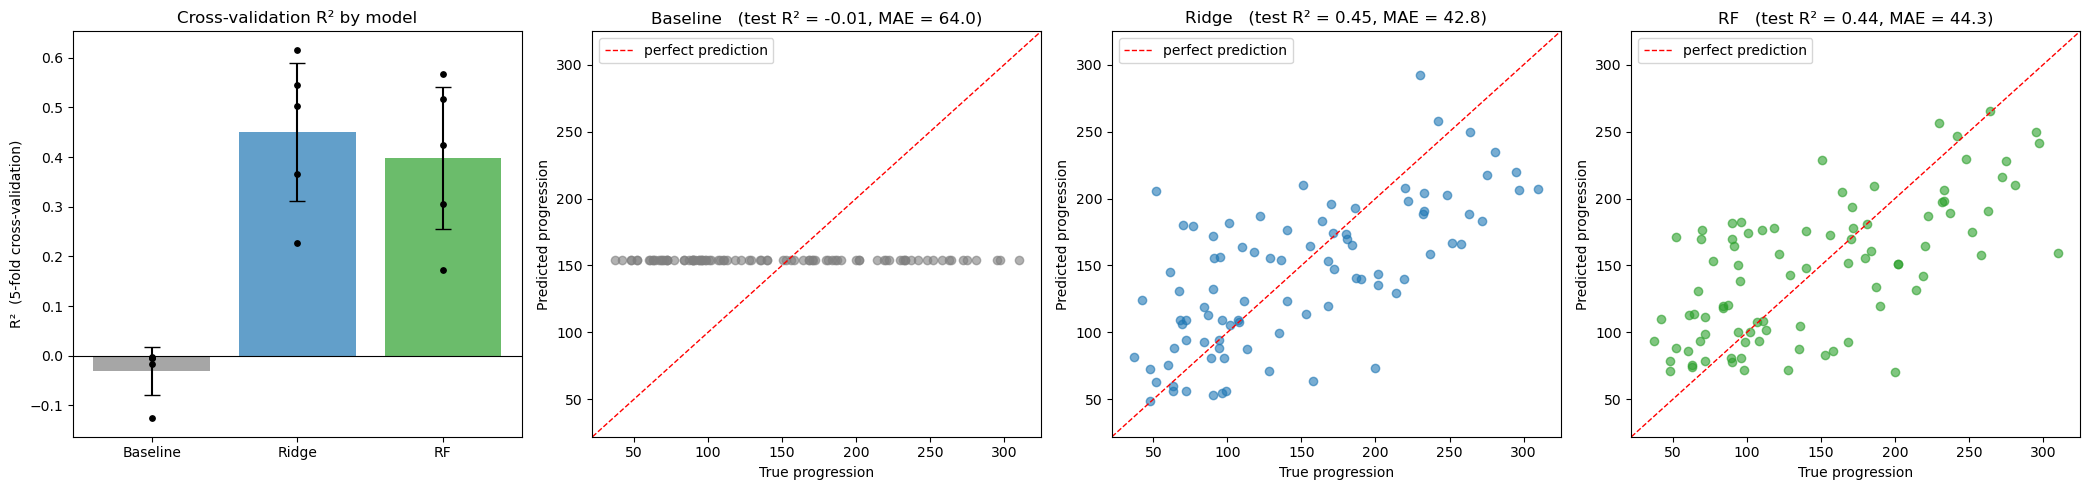

In [17]:
# ===== 5. 可视化不同模型的结果 =====
import numpy as np
import matplotlib.pyplot as plt

# ---- (1) 重新做一次交叉验证，这次把每个模型的 5 个分数都存下来，方便画图 ----
#   字典推导式：{名字: 5个R²分数}，models 就是上面定义的 Baseline / Ridge / RF
cv_scores = {name: cross_val_score(m, X_train, y_train, cv=5, scoring="r2")
             for name, m in models.items()}

# ---- (2) 每个模型都在完整训练集上训练一次，然后预测测试集 ----
test_pred = {}
for name, m in models.items():
    m.fit(X_train, y_train)          # Ridge 的 pipeline 会自动先标准化；Baseline 和 RF 直接用原始数据
    test_pred[name] = m.predict(X_test)

names = list(models)                                   # ["Baseline", "Ridge", "RF"]
colors = ["gray", "tab:blue", "tab:green"]
fig, axes = plt.subplots(1, 4, figsize=(21, 5))

# 图1：交叉验证 R² 柱状图
#   柱子高度 = 5 折的平均值；误差线 = 标准差；黑点 = 每一折各自的分数
means = [cv_scores[n].mean() for n in names]
stds = [cv_scores[n].std() for n in names]
axes[0].bar(names, means, yerr=stds, capsize=6, color=colors, alpha=0.7)
for i, n in enumerate(names):
    axes[0].scatter([i] * len(cv_scores[n]), cv_scores[n], color="black", s=15, zorder=3)
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set_ylabel("R²  (5-fold cross-validation)")
axes[0].set_title("Cross-validation R² by model")

# 图2~4：测试集上 "真实值 vs 预测值" 散点图
lims = [y_test.min() - 15, y_test.max() + 15]          # 坐标范围，三张图保持一致方便比较
for ax, n, c in zip(axes[1:], names, colors):
    ax.scatter(y_test, test_pred[n], alpha=0.6, color=c)
    ax.plot(lims, lims, "r--", linewidth=1, label="perfect prediction")   # 对角线：预测 = 真实
    ax.set_xlim(lims); ax.set_ylim(lims)
    ax.set_xlabel("True progression")
    ax.set_ylabel("Predicted progression")
    ax.set_title("%s   (test R² = %.2f, MAE = %.1f)"
                 % (n, r2_score(y_test, test_pred[n]), mean_absolute_error(y_test, test_pred[n])))
    ax.legend(loc="upper left")

plt.tight_layout()
plt.show()

# 怎么读：
#   1. 图1：Baseline 在 0 附近，Ridge 和 RF 都明显高于它；但黑点很分散（波动约 ±0.14），
#      说明换一折数据，分数变化很大 → Ridge 和 RF 的差距不显著
#   2. Baseline 永远猜训练集的平均值，所以散点是一条水平线
#   3. Ridge 和 RF 的点大致沿对角线分布，但很分散 → 这就是 R² 只有 0.4 左右的"样子"
#   4. 两个模型的点都比对角线"平"：真实值很高的病人被低估，很低的被高估。
#      信息不够时，模型会倾向于往平均值方向猜，这是很典型的现象

## 总结

```
加载数据 → 切分训练/测试 → 标准化（只 fit 训练集）→ 训练 Ridge → 测试集评估（MAE/RMSE/R²）→ 交叉验证对比
```

**回归 vs 分类**（对比上一个乳腺癌例子）：
| | 分类（乳腺癌） | 回归（糖尿病） |
|---|---|---|
| 标签 | 类别（恶性/良性） | 连续数字（进展程度） |
| 切分 | 用 `stratify` 保持类别比例 | 不需要 `stratify` |
| 模型 | LogisticRegression / RandomForestClassifier | Ridge / RandomForestRegressor |
| 指标 | precision、recall、AUC | MAE、RMSE、R² |

# 深度学习小案例：磁瓦表面缺陷检测（CNN 图像分类）

**场景**：工厂流水线上的磁瓦（电机里用的永磁体零件），用相机拍下表面照片，自动判断这个零件**有没有缺陷**。这就是工业里的"视觉质检"。

**数据**：Magnetic Tile Defect 数据集（来自论文 *Saliency of magnetic tile surface defects*），约 1344 张灰度图：
- 952 张**合格**（MT_Free）
- 392 张**有缺陷**，包括气孔、断裂、裂纹、磨损、不均匀 5 种

**和前面两个例子的区别**：前面的输入是一行"人工设计好的数字特征"；这里的输入直接是**图片的像素**，让卷积神经网络（CNN）**自己学**要看什么特征。

流程：下载数据 → 读图 + 切分 → 搭建 CNN → 训练 → 测试集评估

In [18]:
# ===== 1. 下载数据 =====
# 数据集公开放在 GitHub 上，直接 git clone 下来（约 100 MB）
# "!" 开头表示运行终端命令；仓库名最后有两个点，所以给它起个短名字 mt
!git clone -q --depth 1 https://github.com/abin24/Magnetic-tile-defect-datasets..git mt
!ls mt

MT_Blowhole
MT_Break
MT_Crack
MT_Fray
MT_Free
MT_Uneven
README.md
dataset.jpg
dataset.png


In [19]:
# ===== 2. 读取图片 + 切分训练/测试集 =====
import glob
import numpy as np
from PIL import Image                                   # 读图片的库
from sklearn.model_selection import train_test_split

IMG_SIZE = 64        # 把所有图片缩放到 64×64（原图大小不一样，CNN 要求输入尺寸一致；小一点训练快）

X, y = [], []
for folder in sorted(glob.glob("mt/MT_*")):             # 6 个文件夹：MT_Free + 5 种缺陷
    label = 0 if folder.endswith("MT_Free") else 1      # 标签：0 = 合格，1 = 有缺陷（5 种缺陷合成一类）
    for f in glob.glob(folder + "/Imgs/*.jpg"):          # 只读 .jpg 原图（同目录的 .png 是像素级标注，这里不用）
        img = Image.open(f).convert("L")                 # "L" = 转成单通道灰度图
        img = img.resize((IMG_SIZE, IMG_SIZE))          # 统一尺寸
        a = np.array(img, dtype=np.float32)
        a = (a - a.mean()) / (a.std() + 1e-6)            # 每张图自己做标准化：不同照片亮度差别很大，这样网络只关注"图案"而不是"亮暗"
        X.append(a)                                       # （和前面 StandardScaler 是同一个思想，只是对每张图做）
        y.append(label)

X = np.stack(X)[:, None, :, :]   # 形状变成 (图片数, 1, 64, 64)：PyTorch 要求 (数量, 通道, 高, 宽)，灰度图只有 1 个通道
y = np.array(y, dtype=np.int64)   # 标签用 64 位整数，PyTorch 的分类损失函数要求这个类型
print("图片:", X.shape, " 合格:", (y == 0).sum(), " 有缺陷:", (y == 1).sum())

# 和前面一样：80% 训练，20% 测试；stratify 保持两类比例一样
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print("训练集:", len(X_train), " 测试集:", len(X_test))

图片: (1344, 1, 64, 64)  合格: 952  有缺陷: 392
训练集: 1075  测试集: 269


In [20]:
# ===== 3. 搭建 CNN（卷积神经网络）=====
import torch
import torch.nn as nn

torch.manual_seed(42)                                    # 固定随机种子，结果可复现
device = "cuda" if torch.cuda.is_available() else "cpu"  # 有 GPU 就用 GPU，没有就用 CPU（这个小模型 CPU 也够）

# 一个"卷积块" = 卷积 → 批归一化 → 激活 → 池化
#   Conv2d       卷积层：用很多个 3×3 小卷积核（就是图像滤波里的 kernel！）在图上滑动，提取边缘、纹理等特征
#                和图像滤波唯一的区别：kernel 里的数字不是人写的，而是训练时自动学出来的
#   BatchNorm2d  批归一化：把每层的输出重新标准化，让训练更快、更稳定
#   ReLU         激活函数：把负数变成 0，让网络能学非线性的东西
#   MaxPool2d    池化层：每 2×2 取最大值，图片长宽减半
def conv_block(in_ch, out_ch):
    return [nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1), nn.BatchNorm2d(out_ch),
            nn.ReLU(), nn.MaxPool2d(2)]

model = nn.Sequential(
    *conv_block(1, 16),    # 1 通道（灰度）→ 16 个特征图，64×64 → 32×32
    *conv_block(16, 32),   # → 32 个特征图，16×16
    *conv_block(32, 64),   # → 64 个特征图，8×8
    *conv_block(64, 64),   # → 64 个特征图，4×4（越往后，每个特征看到的范围越大，越"抽象"）
    nn.AdaptiveAvgPool2d(1),  # 全局平均池化：每个特征图取平均 → 64 个数（不管缺陷在图上哪个位置都能检测到）
    nn.Flatten(),
    nn.Linear(64, 2),         # 最后输出 2 个分数：合格 / 有缺陷
).to(device)               #  把数据或模型搬到指定的计算设备上，CPU, GPU

print(model)
print("参数个数:", sum(p.numel() for p in model.parameters()))   # 网络要学的数字总数

Sequential(
  (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): ReLU()
  (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (4): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (5): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (6): ReLU()
  (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (8): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (9): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (10): ReLU()
  (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (12): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (13): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (14): ReLU()
  (15): MaxPool2d(kernel_size=2, stride=2,

In [21]:
# ===== 4. 训练 =====
from torch.utils.data import TensorDataset, DataLoader

# DataLoader：每次喂给网络一小批（batch）图片，而不是一次全部喂进去
#   batch_size=32 → 每批 32 张；shuffle=True → 每一轮打乱顺序
train_loader = DataLoader(TensorDataset(torch.tensor(X_train), torch.tensor(y_train)),
                          batch_size=32, shuffle=True)

EPOCHS = 30   # 一个 epoch = 把整个训练集完整看一遍；这里看 30 遍
#   耗时：Colab 免费 CPU 约 4 分钟；菜单 Runtime → Change runtime type 换成 GPU 会快很多

loss_fn = nn.CrossEntropyLoss()                           # 损失函数：衡量预测和真实答案差多少，分类问题的标准选择
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3) # 优化器：根据损失自动调整网络里的数字；lr 是学习率（每次调多少）
# 学习率调度：学习率从 1e-3 慢慢降到 0（余弦曲线）。前期大步走、后期小步微调，最后的模型更稳定
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

for epoch in range(EPOCHS):
    model.train()                                         # 切换到训练模式
    total_loss = 0
    for xb, yb in train_loader:                           # 每次取一批
        # 数据增强：随机左右翻转、上下翻转。翻转后的零件缺陷还是缺陷，相当于免费多出了训练图片
        if torch.rand(1) < 0.5: xb = xb.flip(3)
        if torch.rand(1) < 0.5: xb = xb.flip(2)
        xb, yb = xb.to(device), yb.to(device)

        #深度学习训练的核心 举下山例子！
        loss = loss_fn(model(xb), yb)                     # ① 前向：网络预测，算损失
        optimizer.zero_grad()                             # ② 清空上一批的梯度
        loss.backward()                                   # ③ 反向传播：算出每个参数该往哪个方向调
        optimizer.step()                                  # ④ 更新参数
        total_loss += loss.item() * len(xb)               #  累加这一轮（epoch）的总损失
    scheduler.step()                                      # 每个 epoch 结束，降低一点学习率
    if (epoch + 1) % 5 == 0:                              # 每 5 轮打印一次
        print("epoch %2d  训练损失 %.4f" % (epoch + 1, total_loss / len(X_train)))   # 损失应该逐渐下降

epoch  5  训练损失 0.3778
epoch 10  训练损失 0.2532
epoch 15  训练损失 0.1543
epoch 20  训练损失 0.1057
epoch 25  训练损失 0.0872
epoch 30  训练损失 0.0688


In [22]:
# ===== 5. 测试集评估 =====
from sklearn.metrics import classification_report, confusion_matrix

model.eval()                                              # 切换到评估模式
with torch.no_grad():                                     # 评估时不需要算梯度，更快更省内存
    logits = model(torch.tensor(X_test).to(device))       # 每张图得到 2 个分数
    y_pred = logits.argmax(dim=1).cpu().numpy()           # 取分数大的那一类作为预测

# 和乳腺癌例子一样的评估方法：precision / recall / f1
print(classification_report(y_test, y_pred, target_names=["合格", "有缺陷"]))

# 混淆矩阵：行 = 真实，列 = 预测
#   [[合格→合格, 合格→缺陷(误报)],
#    [缺陷→合格(漏检), 缺陷→缺陷]]
# 质检里"漏检"最危险：坏零件流到客户手里。所以要重点看"有缺陷"那一类的 recall
print(confusion_matrix(y_test, y_pred))

# 注意：合格品占约 71%，所以一个"永远说合格"的模型准确率也有 71%。CNN 必须明显高于这个基线才算学到东西
print("基线准确率（永远猜合格）: %.2f" % (y_test == 0).mean())

              precision    recall  f1-score   support

          合格       0.97      0.99      0.98       191
         有缺陷       0.97      0.94      0.95        78

    accuracy                           0.97       269
   macro avg       0.97      0.96      0.97       269
weighted avg       0.97      0.97      0.97       269

[[189   2]
 [  5  73]]
基线准确率（永远猜合格）: 0.71


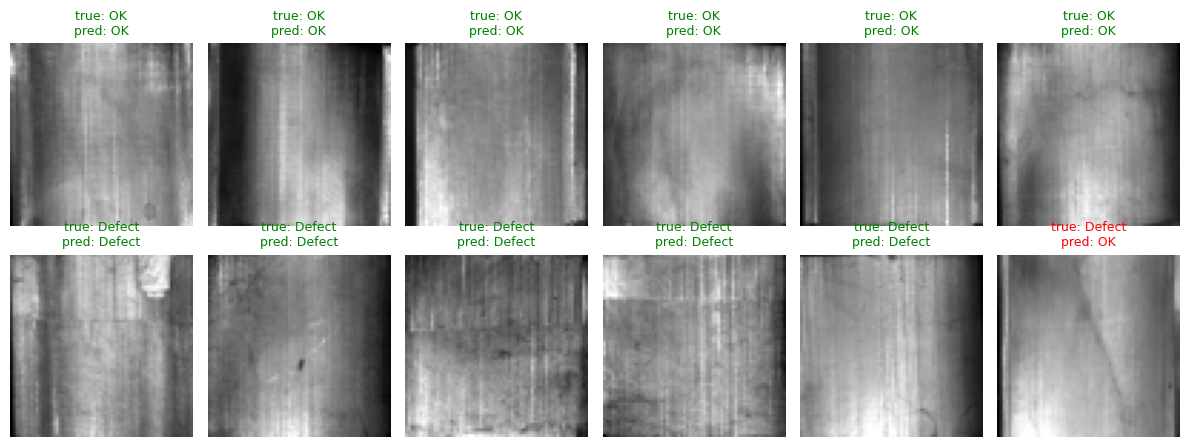

In [23]:
# ===== 6. 看几张测试图片的预测结果 =====
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 6, figsize=(12, 4.5))
# 挑 6 张合格 + 6 张有缺陷的测试图
idx = list(np.where(y_test == 0)[0][:6]) + list(np.where(y_test == 1)[0][:6])
for ax, i in zip(axes.flat, idx):
    ax.imshow(X_test[i, 0], cmap="gray")
    ok = y_pred[i] == y_test[i]
    # 标题：真实 / 预测（英文显示，避免 Colab 缺中文字体出现方框）；预测对是绿色，错是红色
    ax.set_title("true: %s\npred: %s" % (["OK", "Defect"][y_test[i]], ["OK", "Defect"][y_pred[i]]),
                 color="green" if ok else "red", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()